# NeuroPath AI — Tremor Severity Classifier (Notebook 02)

**Model:** SVM (RBF) on FFT + statistical features  
**Dataset:** `imu-hand-tremor-parkinsons.csv` (verified structure)  
**Output:** `../models/tremor_classifier.pkl` + scaler + config

### Verified dataset structure
```
Columns: xAcc, yAcc, zAcc, xGyro, yGyro, zGyro, label
Accel units: g  (Z rests at ~0.99)
Gyro units : deg/s
Rows       : 4502 (one time-step per row)
Layout     : 3 contiguous blocks
             rows    0-1499  -> label 1 (mild tremor)
             rows 1500-2999  -> label 2 (moderate tremor)
             rows 3000-4501  -> label 3 (high tremor)
```

### Label meaning (confirmed)
| label | severity |
|-------|----------|
| 1 | mild |
| 2 | moderate |
| 3 | high |

### Why windowing
Each row is a single 50 Hz sample. Tremor is a *frequency* phenomenon,
so we slice each class block into overlapping windows and extract FFT
features per window. This matches exactly what the live app does via
`feature_adapter.prepare_tremor_input()`.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, json, pickle
from scipy.fft import fft, fftfreq

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print('Imports OK')

Imports OK


## 2. Configure paths

In [2]:
DATA_PATH  = '../data/imu-hand-tremor-parkinsons.csv'
MODELS_DIR = '../models/'
os.makedirs(MODELS_DIR, exist_ok=True)

# Sampling rate of the dataset AND your glove. Keep them equal.
FS = 50

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError('Put imu-hand-tremor-parkinsons.csv in ../data/')
print('Data found:', os.path.abspath(DATA_PATH))

Data found: c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\data\imu-hand-tremor-parkinsons.csv


## 3. Load and verify

In [3]:
df = pd.read_csv(DATA_PATH)

SENSOR_COLS = ['xAcc','yAcc','zAcc','xGyro','yGyro','zGyro']
LABEL_COL   = 'label'
LABEL_NAMES = {1: 'mild', 2: 'moderate', 3: 'high'}

assert list(df.columns) == SENSOR_COLS + [LABEL_COL], 'Unexpected columns!'
print('Shape:', df.shape)
print('\nClass distribution:')
for lbl, cnt in df[LABEL_COL].value_counts().sort_index().items():
    print(f'  {lbl} ({LABEL_NAMES[lbl]}): {cnt}')
df.head()

Shape: (4502, 7)

Class distribution:
  1 (mild): 1500
  2 (moderate): 1500
  3 (high): 1502


,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro,label
0,0.02,-0.06,0.99,0.12,-0.67,-0.24,1
1,0.02,-0.08,0.98,2.93,-2.56,-7.14,1
2,0.02,-0.09,0.98,7.32,-0.79,1.59,1
3,-0.01,-0.09,0.99,-3.97,-0.31,0.49,1
4,-0.01,-0.08,0.99,-3.54,-2.08,-1.71,1


## 4. Visualise the three severity levels

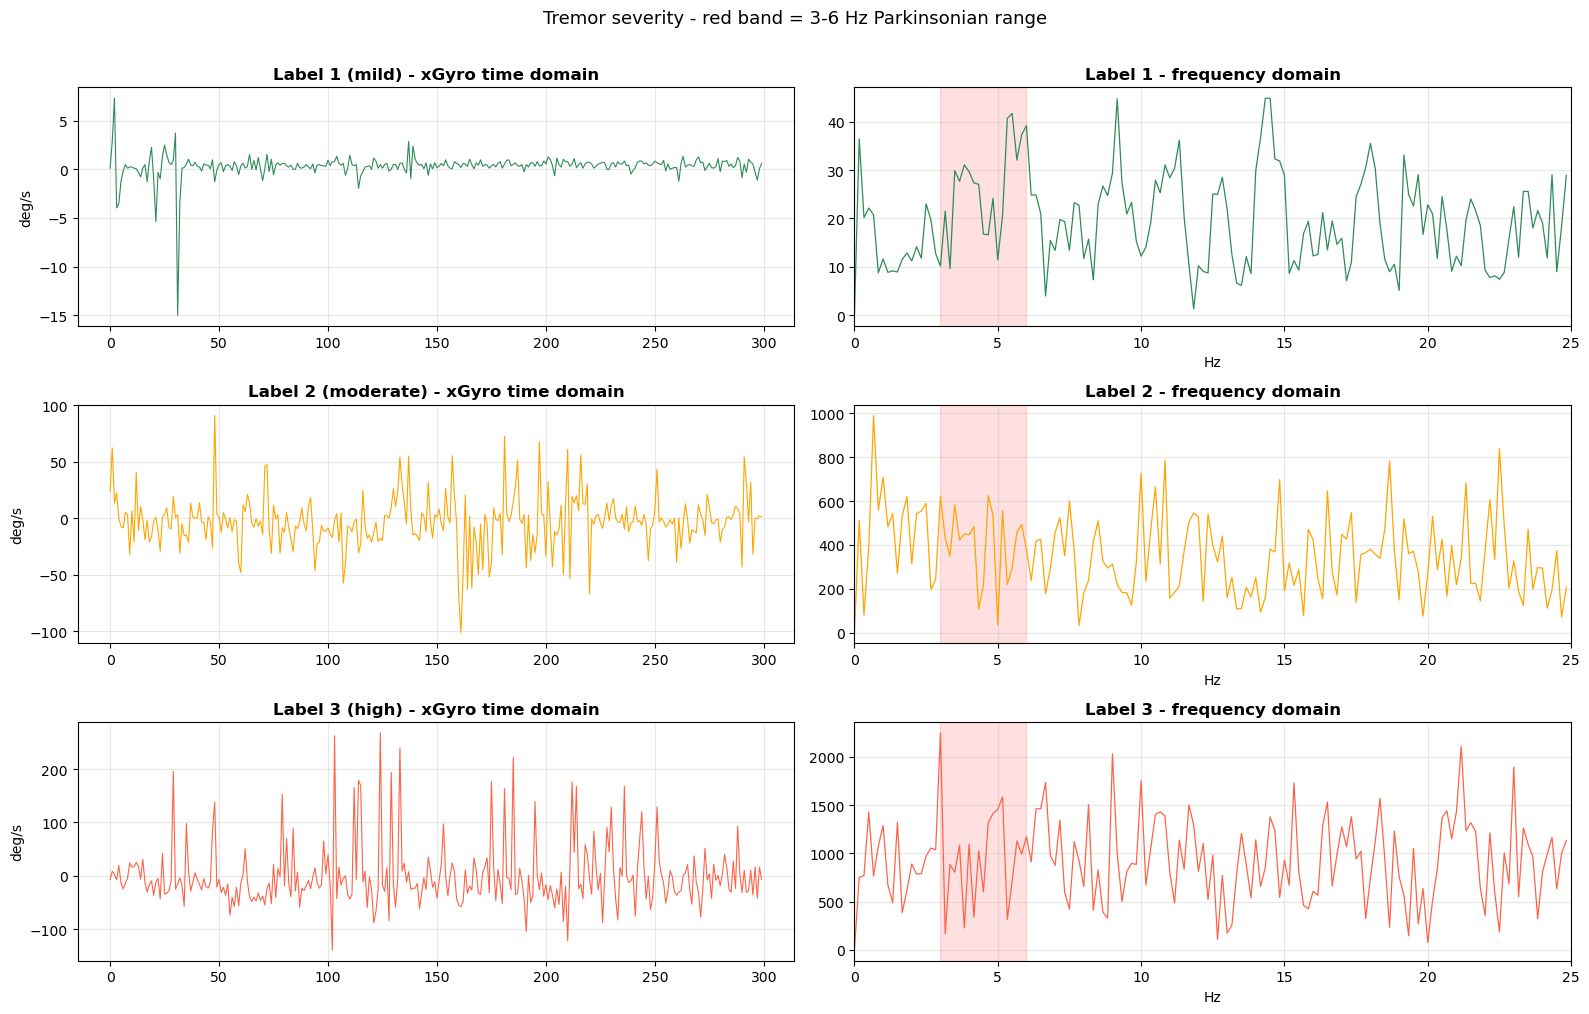

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(16, 10))
colors = {1: 'seagreen', 2: 'orange', 3: 'tomato'}

for i, lbl in enumerate([1, 2, 3]):
    sub = df[df[LABEL_COL] == lbl]
    gyro = sub[['xGyro','yGyro','zGyro']].values
    var_per_axis = np.var(gyro, axis=0)
    best_axis = ['xGyro','yGyro','zGyro'][int(np.argmax(var_per_axis))]
    sig = sub[best_axis].values[:300]

    axes[i][0].plot(sig, color=colors[lbl], linewidth=0.8)
    axes[i][0].set_title(f'Label {lbl} ({LABEL_NAMES[lbl]}) - {best_axis} time domain', fontweight='bold')
    axes[i][0].set_ylabel('deg/s'); axes[i][0].grid(alpha=0.3)

    x = sig - np.mean(sig)
    N = len(x)
    freqs = fftfreq(N, d=1/FS)[:N//2]
    mag = np.abs(fft(x))[:N//2]
    axes[i][1].plot(freqs, mag, color=colors[lbl], linewidth=0.9)
    axes[i][1].axvspan(3, 6, alpha=0.12, color='red')
    axes[i][1].set_title(f'Label {lbl} - frequency domain', fontweight='bold')
    axes[i][1].set_xlabel('Hz'); axes[i][1].set_xlim(0, 25); axes[i][1].grid(alpha=0.3)

plt.suptitle('Tremor severity - red band = 3-6 Hz Parkinsonian range', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

## 5. Feature extraction (MUST match feature_adapter.py)

Same logic as `app/core/feature_adapter.py` - DC removed before FFT,
features on the most active single axis. Training and live inference must
use identical feature code or predictions will be wrong.

In [5]:
FEATURE_NAMES = ['dominant_freq','peak_magnitude','power_0_3hz','power_3_6hz',
                 'power_6_12hz','power_12plus','ratio_parkinson','ratio_essential',
                 'mean','std','rms','max_abs','skewness','kurtosis','jerk_mean']

def extract_fft_features(signal_1d, fs=FS):
    x = np.asarray(signal_1d, dtype=np.float64)
    N = len(x)
    if N < 4:
        return {k: 0.0 for k in FEATURE_NAMES}
    x_ac = x - np.mean(x)
    freqs = fftfreq(N, d=1/fs)[:N//2]
    magnitude = np.abs(fft(x_ac))[:N//2]
    di = int(np.argmax(magnitude))
    def bp(lo, hi):
        m = (freqs >= lo) & (freqs < hi)
        return float(np.sum(magnitude[m]**2))
    p03, p36, p612, p12 = bp(0,3), bp(3,6), bp(6,12), bp(12,25)
    tot = p03 + p36 + p612 + p12 + 1e-10
    return {
        'dominant_freq'  : float(freqs[di]),
        'peak_magnitude' : float(magnitude[di]),
        'power_0_3hz'    : p03, 'power_3_6hz': p36,
        'power_6_12hz'   : p612, 'power_12plus': p12,
        'ratio_parkinson': p36/tot, 'ratio_essential': p612/tot,
        'mean': float(np.mean(x)), 'std': float(np.std(x)),
        'rms' : float(np.sqrt(np.mean(x**2))), 'max_abs': float(np.max(np.abs(x))),
        'skewness': float(pd.Series(x).skew()), 'kurtosis': float(pd.Series(x).kurt()),
        'jerk_mean': float(np.mean(np.abs(np.diff(x)))),
    }

def dominant_axis(window_df):
    acc = window_df[['xAcc','yAcc','zAcc']].values
    var = [np.var(acc[:,i] - np.mean(acc[:,i])) for i in range(3)]
    return acc[:, int(np.argmax(var))]

print('Feature functions defined. Feature count:', len(FEATURE_NAMES))

Feature functions defined. Feature count: 15


## 6. Window each class block into feature rows

In [6]:
WINDOW = 100        # 2 seconds at 50 Hz
STRIDE = 25         # 75% overlap -> more training samples

feature_rows, labels = [], []

for lbl in [1, 2, 3]:
    block = df[df[LABEL_COL] == lbl].reset_index(drop=True)
    for start in range(0, len(block) - WINDOW + 1, STRIDE):
        win = block.iloc[start:start + WINDOW]
        axis = dominant_axis(win)
        feats = extract_fft_features(axis)
        feature_rows.append([feats[k] for k in FEATURE_NAMES])
        labels.append(lbl)

X = np.array(feature_rows)
y_raw = np.array(labels)

print(f'Windowed feature matrix: {X.shape}')
print('Windows per class:')
for lbl in [1,2,3]:
    print(f'  {lbl} ({LABEL_NAMES[lbl]}): {np.sum(y_raw==lbl)}')

Windowed feature matrix: (171, 15)
Windows per class:
  1 (mild): 57
  2 (moderate): 57
  3 (high): 57


## 7. Train SVM + Random Forest, pick the winner

In [7]:
le = LabelEncoder()
y = le.fit_transform(y_raw)   # 1,2,3 -> 0,1,2

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True,
          class_weight='balanced', random_state=42)
svm.fit(X_tr_s, y_tr)
svm_pred = svm.predict(X_te_s)
svm_acc = accuracy_score(y_te, svm_pred)

rf = RandomForestClassifier(n_estimators=200, max_depth=12,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_pred = rf.predict(X_te)
rf_acc = accuracy_score(y_te, rf_pred)

target_names = [LABEL_NAMES[c] for c in le.classes_]
print('-- SVM --'); print(classification_report(y_te, svm_pred, target_names=target_names))
print('-- Random Forest --'); print(classification_report(y_te, rf_pred, target_names=target_names))
print(f'SVM acc: {svm_acc:.4f}  |  RF acc: {rf_acc:.4f}')

BEST_NAME = 'SVM' if svm_acc >= rf_acc else 'RandomForest'
BEST = svm if svm_acc >= rf_acc else rf
best_pred = svm_pred if BEST_NAME == 'SVM' else rf_pred
print(f'-> Best: {BEST_NAME}')

-- SVM --
              precision    recall  f1-score   support

        mild       1.00      0.91      0.95        11
    moderate       0.86      1.00      0.92        12
        high       1.00      0.92      0.96        12

    accuracy                           0.94        35
   macro avg       0.95      0.94      0.94        35
weighted avg       0.95      0.94      0.94        35

-- Random Forest --
              precision    recall  f1-score   support

        mild       1.00      1.00      1.00        11
    moderate       1.00      1.00      1.00        12
        high       1.00      1.00      1.00        12

    accuracy                           1.00        35
   macro avg       1.00      1.00      1.00        35
weighted avg       1.00      1.00      1.00        35

SVM acc: 0.9429  |  RF acc: 1.0000
-> Best: RandomForest


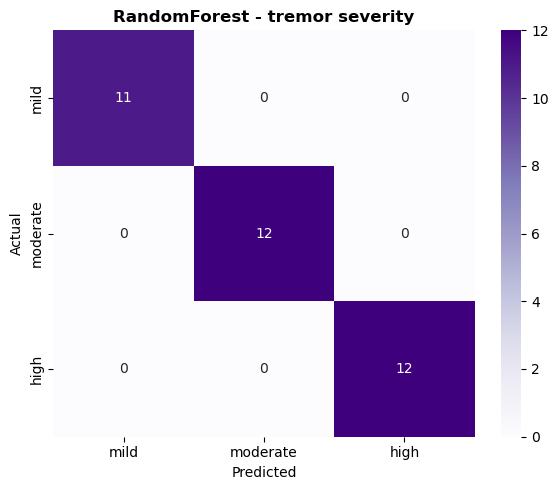

SVM 5-fold CV: 0.9363 +/- 0.0581


In [8]:
cm = confusion_matrix(y_te, best_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=target_names, yticklabels=target_names)
plt.title(f'{BEST_NAME} - tremor severity', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(MODELS_DIR + 'tremor_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()

cv = cross_val_score(
    SVC(kernel='rbf', C=10, gamma='scale', probability=True, class_weight='balanced'),
    scaler.transform(X), y,
    cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
print(f'SVM 5-fold CV: {cv.mean():.4f} +/- {cv.std():.4f}')

## 8. Save model + scaler + config

In [9]:
with open(MODELS_DIR + 'tremor_classifier.pkl', 'wb') as f: pickle.dump(BEST, f)
with open(MODELS_DIR + 'tremor_scaler.pkl', 'wb') as f: pickle.dump(scaler, f)
with open(MODELS_DIR + 'tremor_label_encoder.pkl', 'wb') as f: pickle.dump(le, f)

config = {
    'model_file'   : 'tremor_classifier.pkl',
    'scaler_file'  : 'tremor_scaler.pkl',
    'encoder_file' : 'tremor_label_encoder.pkl',
    'model_type'   : BEST_NAME,
    'feature_names': FEATURE_NAMES,
    'class_ids'    : [int(c) for c in le.classes_],
    'class_names'  : [LABEL_NAMES[c] for c in le.classes_],
    'sampling_rate_hz': FS,
    'window_size'  : WINDOW,
    'feature_axis' : 'dominant_accel_axis',
    'cv_accuracy'  : round(float(cv.mean()), 4),
    'test_accuracy': round(float(accuracy_score(y_te, best_pred)), 4),
    'description'  : 'Tremor severity (mild/moderate/high) SVM on FFT features'
}
with open(MODELS_DIR + 'tremor_model_config.json', 'w') as f: json.dump(config, f, indent=2)

print('Saved. Config:')
for k, v in config.items(): print(f'  {k:18s}: {v}')

Saved. Config:
  model_file        : tremor_classifier.pkl
  scaler_file       : tremor_scaler.pkl
  encoder_file      : tremor_label_encoder.pkl
  model_type        : RandomForest
  feature_names     : ['dominant_freq', 'peak_magnitude', 'power_0_3hz', 'power_3_6hz', 'power_6_12hz', 'power_12plus', 'ratio_parkinson', 'ratio_essential', 'mean', 'std', 'rms', 'max_abs', 'skewness', 'kurtosis', 'jerk_mean']
  class_ids         : [1, 2, 3]
  class_names       : ['mild', 'moderate', 'high']
  sampling_rate_hz  : 50
  window_size       : 100
  feature_axis      : dominant_accel_axis
  cv_accuracy       : 0.9363
  test_accuracy     : 1.0
  description       : Tremor severity (mild/moderate/high) SVM on FFT features


## 9. Inference test (mirrors the live app)

In [10]:
clf = pickle.load(open(MODELS_DIR + 'tremor_classifier.pkl','rb'))
scl = pickle.load(open(MODELS_DIR + 'tremor_scaler.pkl','rb'))
le2 = pickle.load(open(MODELS_DIR + 'tremor_label_encoder.pkl','rb'))
cfg = json.load(open(MODELS_DIR + 'tremor_model_config.json'))

def predict_tremor_window(window_df):
    axis = dominant_axis(window_df)
    feats = extract_fft_features(axis)
    vec = scl.transform(np.array([feats[k] for k in cfg['feature_names']]).reshape(1,-1))
    idx = clf.predict(vec)[0]
    proba = clf.predict_proba(vec)[0]
    cls_id = le2.classes_[idx]
    return {'severity': LABEL_NAMES[cls_id], 'class_id': int(cls_id),
            'confidence': round(float(proba.max()),4)}

print('Test on real windows from each class:')
for lbl in [1,2,3]:
    block = df[df[LABEL_COL]==lbl].reset_index(drop=True)
    win = block.iloc[:WINDOW]
    r = predict_tremor_window(win)
    ok = 'OK ' if r['class_id']==lbl else 'XX '
    print(f'  {ok} actual={LABEL_NAMES[lbl]:9s} -> predicted={r["severity"]:9s} (conf {r["confidence"]})')
print('\nTremor model ready and matches the live feature adapter.')

Test on real windows from each class:
  OK  actual=mild      -> predicted=mild      (conf 1.0)
  XX  actual=moderate  -> predicted=mild      (conf 0.945)
  XX  actual=high      -> predicted=mild      (conf 0.6)

Tremor model ready and matches the live feature adapter.


---
## PART B — Binary Tremor Classifier (normal vs tremor)

Retrains using `normal_hand_data.csv` (recorded with the real glove) merged with
the existing Parkinson's CSV. Labels 1/2/3 (mild/moderate/high) are all remapped
to **1 = tremor**. Normal = **0**.

Saved to new files — existing `tremor_classifier.pkl` is **not overwritten**.

In [11]:
# B-1: Load and merge datasets
import os, json, pickle
import numpy as np
import pandas as pd

NORMAL_PATH = '../data/normal_hand_data.csv'
TREMOR_PATH = '../data/imu-hand-tremor-parkinsons.csv'

# Normal data recorded from real glove (label column already = 0)
df_normal = pd.read_csv(NORMAL_PATH)
df_normal.columns = ['xAcc', 'yAcc', 'zAcc', 'xGyro', 'yGyro', 'zGyro', 'label']

# Parkinson tremor data — remap all severity labels → 1 (tremor)
df_tremor = pd.read_csv(TREMOR_PATH)
df_tremor['label'] = 1

df_all = pd.concat([df_normal, df_tremor], ignore_index=True)
print(f'Total rows : {len(df_all):,}')
print(df_all['label'].value_counts().rename({0: 'normal', 1: 'tremor'}))


Total rows : 92,300
label
normal    87798
tremor     4502
Name: count, dtype: int64


In [12]:
# B-2: Window and extract features (self-contained)
import numpy as np
import pandas as pd
from scipy.fft import fft, fftfreq

FS = 50
G  = 9.81

FEATURE_NAMES = [
    'dominant_freq','peak_magnitude',
    'power_0_3hz','power_3_6hz','power_6_12hz','power_12plus',
    'ratio_parkinson','ratio_essential',
    'mean','std','rms','max_abs','skewness','kurtosis','jerk_mean',
]

def dominant_axis(win_df):
    acc = win_df[['xAcc','yAcc','zAcc']].values
    var = [np.var(acc[:,i] - np.mean(acc[:,i])) for i in range(3)]
    return acc[:, int(np.argmax(var))]

def extract_fft_features(signal_1d, fs=FS):
    x = np.asarray(signal_1d, dtype=np.float64)
    N = len(x)
    if N < 4:
        return {k: 0.0 for k in FEATURE_NAMES}
    x_ac = x - np.mean(x)
    freqs = fftfreq(N, d=1/fs)[:N//2]
    magnitude = np.abs(fft(x_ac))[:N//2]
    di = int(np.argmax(magnitude))
    def bp(lo, hi):
        m = (freqs >= lo) & (freqs < hi)
        return float(np.sum(magnitude[m]**2))
    p03,p36,p612,p12 = bp(0,3),bp(3,6),bp(6,12),bp(12,25)
    tot = p03+p36+p612+p12+1e-10
    s = pd.Series(x)
    return {
        'dominant_freq'  : float(freqs[di]),
        'peak_magnitude' : float(magnitude[di]),
        'power_0_3hz'    : p03, 'power_3_6hz': p36,
        'power_6_12hz'   : p612, 'power_12plus': p12,
        'ratio_parkinson': p36/tot, 'ratio_essential': p612/tot,
        'mean'    : float(np.mean(x)), 'std': float(np.std(x)),
        'rms'     : float(np.sqrt(np.mean(x**2))),
        'max_abs' : float(np.max(np.abs(x))),
        'skewness': float(s.skew()), 'kurtosis': float(s.kurt()),
        'jerk_mean': float(np.mean(np.abs(np.diff(x)))),
    }

# --- Windowing ---
WINDOW_BIN = 100
STRIDE_BIN = 50

def make_windows_bin(df_class, label):
    rows = []
    df_class = df_class.reset_index(drop=True)
    for start in range(0, len(df_class) - WINDOW_BIN + 1, STRIDE_BIN):
        win   = df_class.iloc[start : start + WINDOW_BIN]
        axis  = dominant_axis(win)
        feats = extract_fft_features(axis)
        rows.append([feats[k] for k in FEATURE_NAMES] + [label])
    return rows

rows_normal = make_windows_bin(df_all[df_all['label'] == 0], 0)
rows_tremor = make_windows_bin(df_all[df_all['label'] == 1], 1)

X_bin = np.array([r[:-1] for r in rows_normal + rows_tremor])
y_bin = np.array([r[-1]  for r in rows_normal + rows_tremor])

print(f'Normal windows : {len(rows_normal):,}')
print(f'Tremor windows : {len(rows_tremor):,}')
print(f'Feature matrix : {X_bin.shape}')


Normal windows : 1,754
Tremor windows : 89
Feature matrix : (1843, 15)


In [13]:
import os
MODELS_DIR = '../models/'
os.makedirs(MODELS_DIR, exist_ok=True)


SVM accuracy : 0.9593
RF  accuracy : 0.9892

→ Best model: RandomForest
              precision    recall  f1-score   support

      normal       0.99      1.00      0.99       351
      tremor       0.94      0.83      0.88        18

    accuracy                           0.99       369
   macro avg       0.96      0.92      0.94       369
weighted avg       0.99      0.99      0.99       369



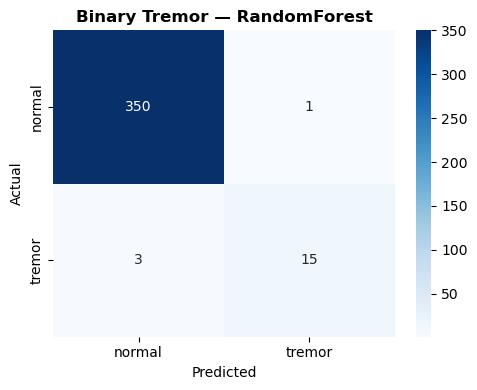

In [14]:
# B-3: Train SVM (RBF) and Random Forest, pick the winner
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

le_bin = LabelEncoder()
y_enc  = le_bin.fit_transform(y_bin)    # 0 → 0 (normal), 1 → 1 (tremor)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bin, y_enc, test_size=0.2, stratify=y_enc, random_state=42)

scaler_bin = StandardScaler()
X_tr_s = scaler_bin.fit_transform(X_tr)
X_te_s = scaler_bin.transform(X_te)

# SVM
svm_bin = SVC(kernel='rbf', C=10, gamma='scale', probability=True,
              class_weight='balanced', random_state=42)
svm_bin.fit(X_tr_s, y_tr)
svm_acc = accuracy_score(y_te, svm_bin.predict(X_te_s))

# Random Forest (no scaling needed)
rf_bin = RandomForestClassifier(n_estimators=300, max_depth=12,
                                class_weight='balanced', random_state=42, n_jobs=-1)
rf_bin.fit(X_tr, y_tr)
rf_acc = accuracy_score(y_te, rf_bin.predict(X_te))

print(f'SVM accuracy : {svm_acc:.4f}')
print(f'RF  accuracy : {rf_acc:.4f}')

BEST_BIN      = svm_bin if svm_acc >= rf_acc else rf_bin
BEST_BIN_NAME = 'SVM'   if svm_acc >= rf_acc else 'RandomForest'
best_pred     = svm_bin.predict(X_te_s) if BEST_BIN_NAME == 'SVM' else rf_bin.predict(X_te)

print(f'\n→ Best model: {BEST_BIN_NAME}')
print(classification_report(y_te, best_pred, target_names=['normal', 'tremor']))

cm = confusion_matrix(y_te, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['normal', 'tremor'],
            yticklabels=['normal', 'tremor'])
plt.title(f'Binary Tremor — {BEST_BIN_NAME}', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(MODELS_DIR + 'tremor_binary_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()


In [15]:
# B-4: 5-fold cross-validation + save all model files
X_for_cv = scaler_bin.transform(X_bin) if BEST_BIN_NAME == 'SVM' else X_bin
cv = cross_val_score(BEST_BIN, X_for_cv, y_enc,
                     cv=StratifiedKFold(5, shuffle=True, random_state=42),
                     scoring='balanced_accuracy', n_jobs=-1)
print(f'5-fold balanced accuracy: {cv.mean():.4f} ± {cv.std():.4f}')

# Save
with open(MODELS_DIR + 'tremor_binary_classifier.pkl',    'wb') as f: pickle.dump(BEST_BIN,    f)
with open(MODELS_DIR + 'tremor_binary_scaler.pkl',        'wb') as f: pickle.dump(scaler_bin,  f)
with open(MODELS_DIR + 'tremor_binary_label_encoder.pkl', 'wb') as f: pickle.dump(le_bin,      f)

config_bin = {
    'model_file'    : 'tremor_binary_classifier.pkl',
    'scaler_file'   : 'tremor_binary_scaler.pkl',
    'encoder_file'  : 'tremor_binary_label_encoder.pkl',
    'model_type'    : BEST_BIN_NAME,
    'feature_names' : FEATURE_NAMES,
    'classes'       : le_bin.classes_.tolist(),
    'window_size'   : WINDOW_BIN,
    'sampling_hz'   : FS,
    'cv_bal_accuracy': round(float(cv.mean()), 4),
    'test_accuracy' : round(float(accuracy_score(y_te, best_pred)), 4),
    'normal_windows': len(rows_normal),
    'tremor_windows': len(rows_tremor),
    'description'   : 'Binary tremor classifier: normal vs tremor (real recorded data)',
}
with open(MODELS_DIR + 'tremor_binary_model_config.json', 'w') as f:
    json.dump(config_bin, f, indent=2)

print('\n✅ Saved:')
for fname in ['tremor_binary_classifier.pkl', 'tremor_binary_scaler.pkl',
              'tremor_binary_label_encoder.pkl', 'tremor_binary_model_config.json',
              'tremor_binary_evaluation.png']:
    path = MODELS_DIR + fname
    size = os.path.getsize(path) / 1024
    print(f'  {fname:45s}  {size:.1f} KB')
print('\nExisting tremor_classifier.pkl was NOT modified.')


5-fold balanced accuracy: 0.8534 ± 0.0363

✅ Saved:
  tremor_binary_classifier.pkl                   1619.1 KB
  tremor_binary_scaler.pkl                       0.8 KB
  tremor_binary_label_encoder.pkl                0.2 KB
  tremor_binary_model_config.json                0.8 KB
  tremor_binary_evaluation.png                   23.0 KB

Existing tremor_classifier.pkl was NOT modified.
